CSV CV: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random\hasil_cv_ringkasan.csv
CSV prediksi test: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random\prediksi_test_semua_model.csv
Folder gambar output: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random\Visualisasi


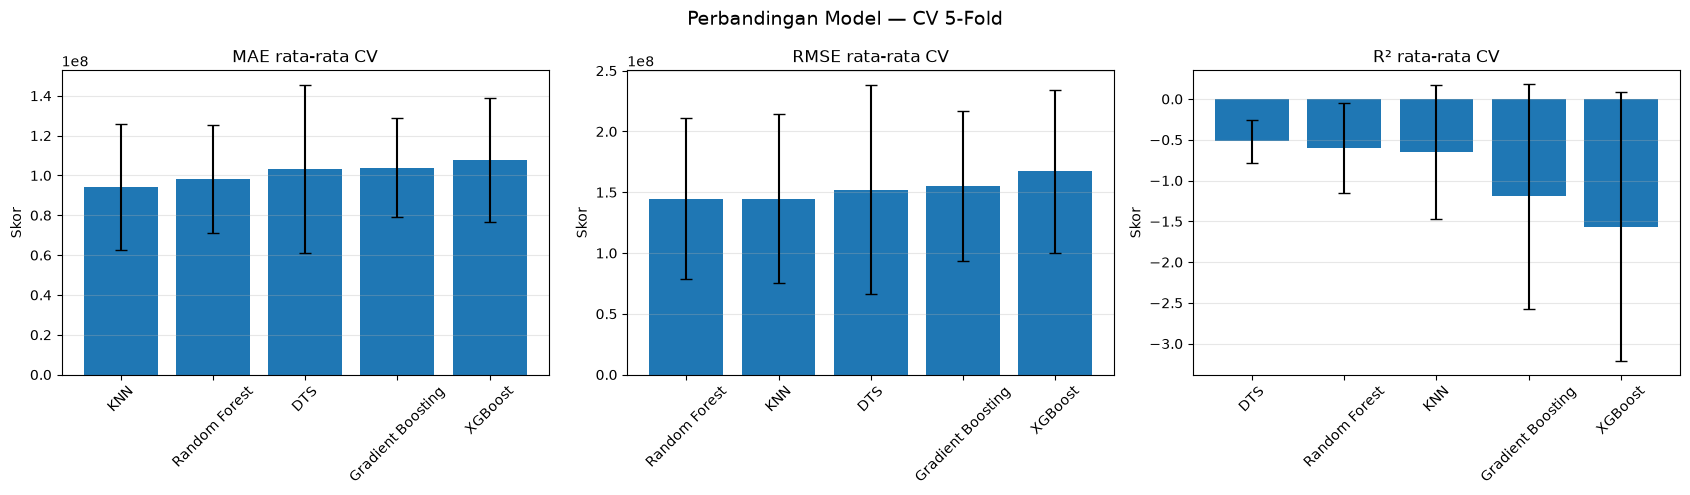

Gambar ringkasan CV disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random\Visualisasi\ringkasan_cross_validation.png


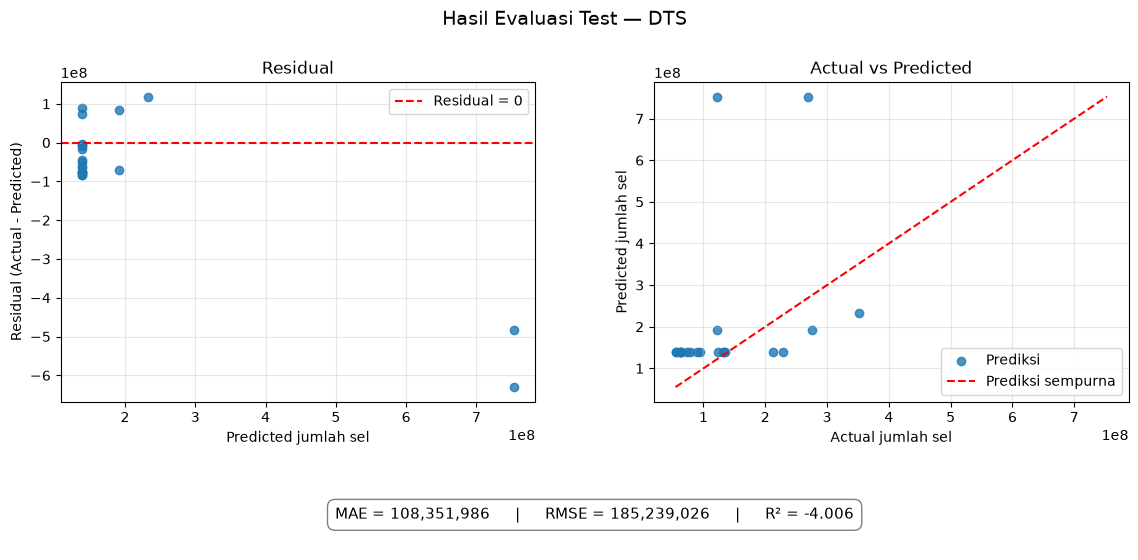

Gambar disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random\Visualisasi\dts_evaluasi_test.png


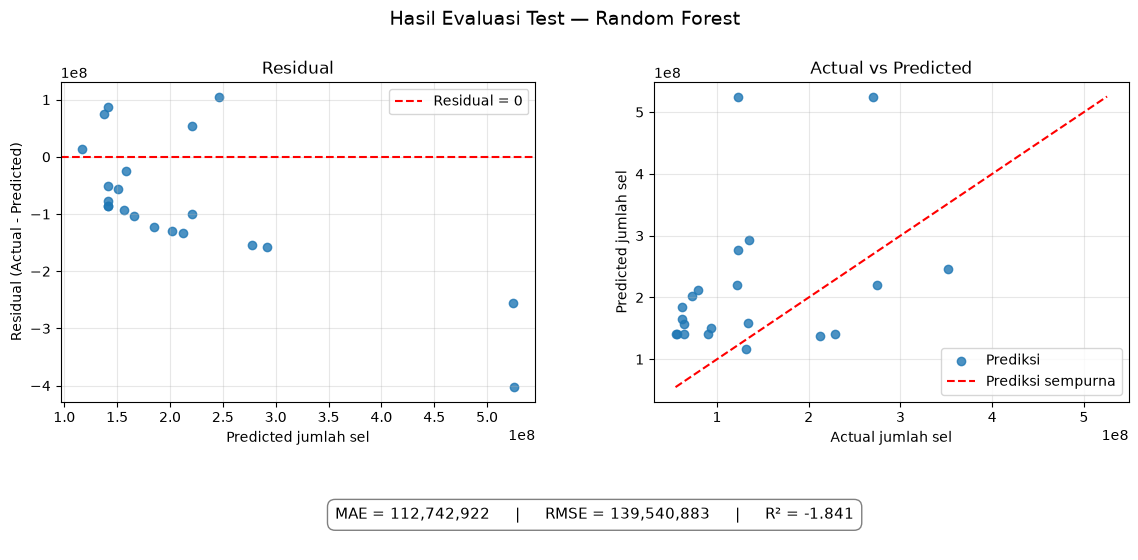

Gambar disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random\Visualisasi\random_forest_evaluasi_test.png


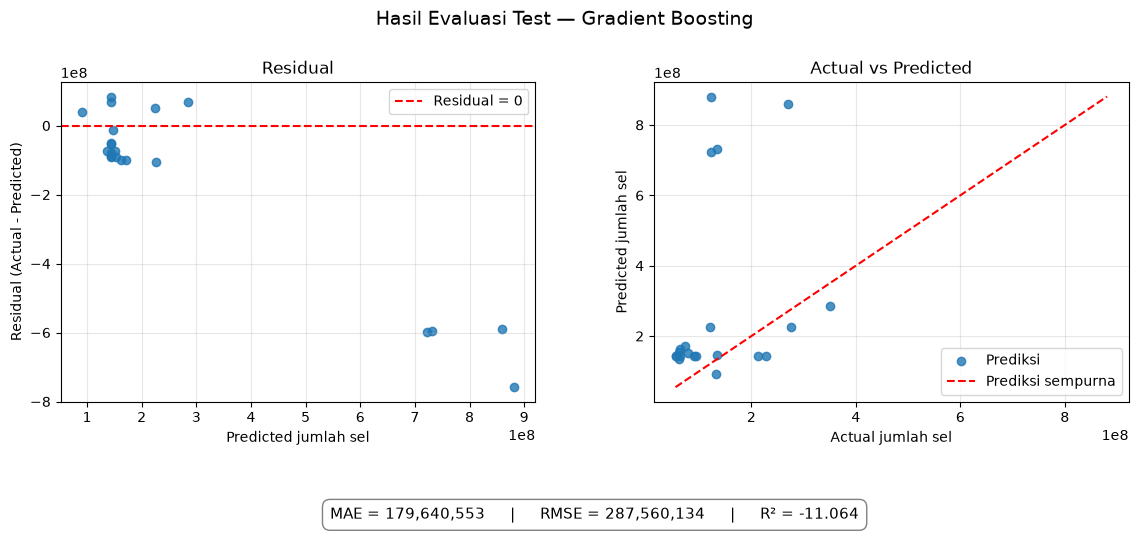

Gambar disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random\Visualisasi\gradient_boosting_evaluasi_test.png


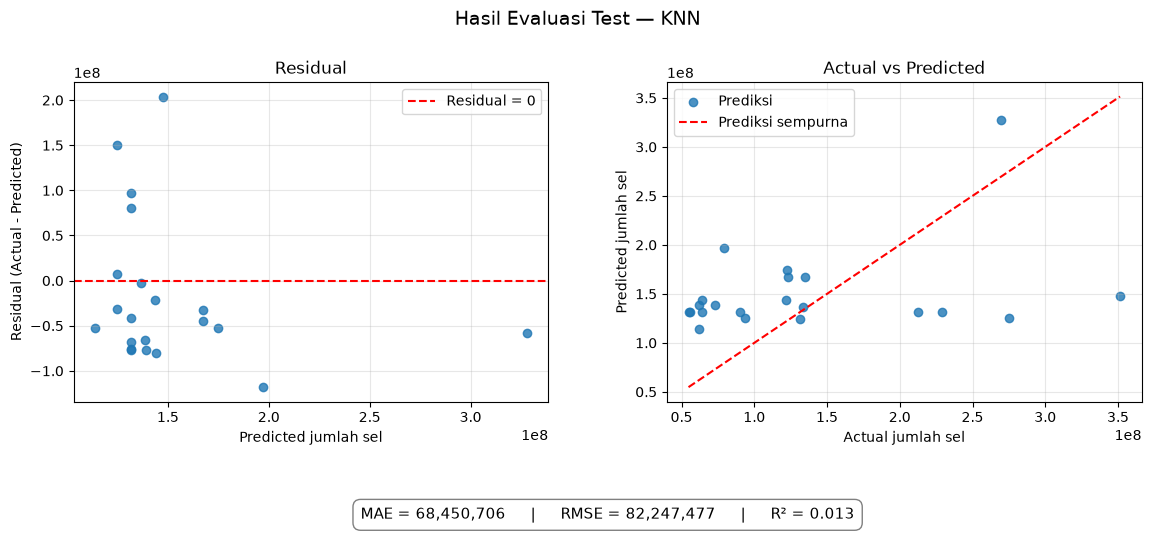

Gambar disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random\Visualisasi\knn_evaluasi_test.png


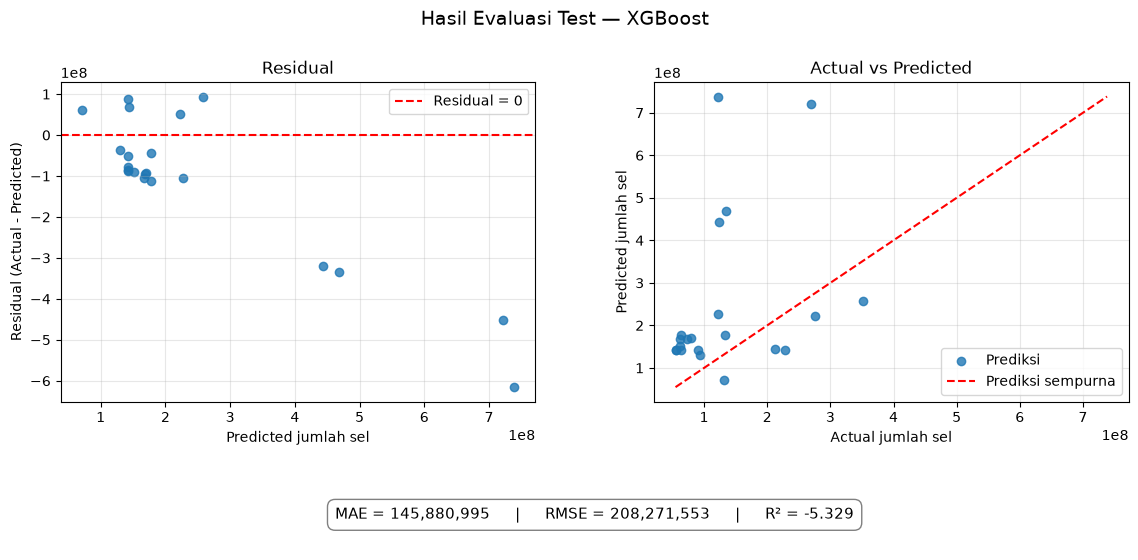

Gambar disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random\Visualisasi\xgboost_evaluasi_test.png


,Model,MAE,RMSE,R2
0,DTS,1.083520e+08,1.852390e+08,-4.006
1,Random Forest,1.127429e+08,1.395409e+08,-1.841
2,Gradient Boosting,1.796406e+08,2.875601e+08,-11.064
3,KNN,6.845071e+07,8.224748e+07,0.013
4,XGBoost,1.458810e+08,2.082716e+08,-5.329


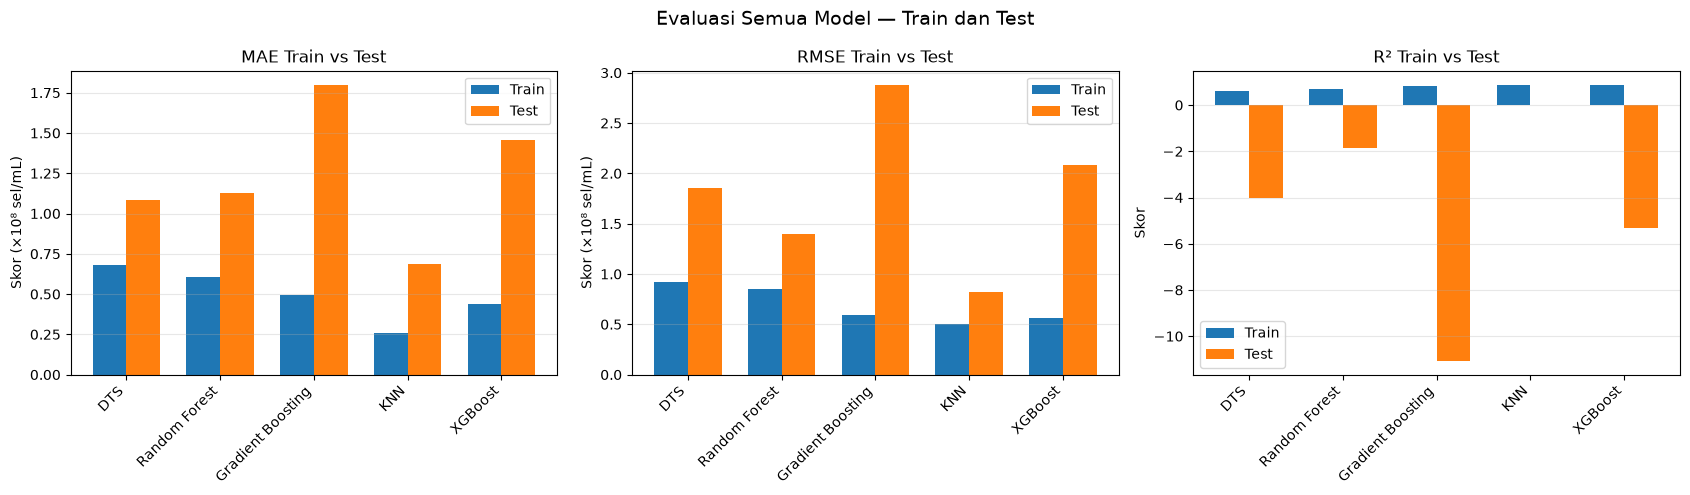

Grafik Train vs Test disimpan: D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random\Visualisasi\perbandingan_train_test.png


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# 1. Tentukan folder CSV hasil training
# ============================================================

# Kaggle: CSV biasanya tersimpan di /kaggle/working.
# Lokal: sesuaikan path folder jika CSV berada di tempat lain.
folder_output = Path(r"D:\00 Kuliah\TA\Experiment\Model\5 ML\Hasil\Random")

file_cv_ringkasan = folder_output / "hasil_cv_ringkasan.csv"
file_prediksi_test = folder_output / "prediksi_test_semua_model.csv"

for file_hasil in (file_cv_ringkasan, file_prediksi_test):
    if not file_hasil.is_file():
        raise FileNotFoundError(
            f"File tidak ditemukan: {file_hasil}\n"
            "Periksa folder_output dan pastikan CSV hasil training "
            "sudah berada di folder tersebut."
        )

# Folder untuk menyimpan satu gambar per model.
folder_gambar = folder_output / "Visualisasi"
folder_gambar.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. Baca CSV hasil CV dan prediksi test
# ============================================================

tabel_cv = pd.read_csv(file_cv_ringkasan, encoding="utf-8-sig")
data_test = pd.read_csv(file_prediksi_test, encoding="utf-8-sig")

kolom_cv_wajib = {
    "Model",
    "MAE rata-rata",
    "MAE std",
    "RMSE rata-rata",
    "RMSE std",
    "R2 rata-rata",
    "R2 std",
}
kolom_test_wajib = {"actual"}

if not kolom_cv_wajib.issubset(tabel_cv.columns):
    kolom_hilang = sorted(kolom_cv_wajib - set(tabel_cv.columns))
    raise KeyError(
        f"Kolom wajib tidak ditemukan di {file_cv_ringkasan.name}: "
        f"{kolom_hilang}"
    )

if not kolom_test_wajib.issubset(data_test.columns):
    raise KeyError(
        f"Kolom 'actual' tidak ditemukan di {file_prediksi_test.name}."
    )

kolom_prediksi = [
    nama_kolom
    for nama_kolom in data_test.columns
    if nama_kolom.startswith("predicted_")
]

if not kolom_prediksi:
    raise ValueError(
        f"Tidak ditemukan kolom 'predicted_...' di {file_prediksi_test.name}."
    )

actual = pd.to_numeric(data_test["actual"], errors="coerce").to_numpy(dtype=float)

if not np.isfinite(actual).all():
    raise ValueError("Kolom actual berisi nilai kosong atau bukan angka.")

if len(actual) < 2:
    raise ValueError("Diperlukan setidaknya dua sampel test untuk menghitung R².")

print(f"CSV CV: {file_cv_ringkasan}")
print(f"CSV prediksi test: {file_prediksi_test}")
print(f"Folder gambar output: {folder_gambar}")


# ============================================================
# 3. Visualisasikan ringkasan CV semua model
# ============================================================

metrik_cv_plot = [
    ("MAE rata-rata", "MAE std", "MAE rata-rata CV", True),
    ("RMSE rata-rata", "RMSE std", "RMSE rata-rata CV", True),
    ("R2 rata-rata", "R2 std", "R² rata-rata CV", False),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (kolom_skor, kolom_std, judul, urut_naik) in zip(
    axes,
    metrik_cv_plot,
):
    plot_data = tabel_cv.sort_values(
        kolom_skor,
        ascending=urut_naik,
    )

    ax.bar(
        plot_data["Model"],
        plot_data[kolom_skor],
        yerr=plot_data[kolom_std],
        capsize=4,
    )
    ax.set_title(judul)
    ax.set_ylabel("Skor")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Perbandingan Model — CV 5-Fold", fontsize=14)
fig.tight_layout()

file_gambar_cv = folder_gambar / "ringkasan_cross_validation.png"
fig.savefig(file_gambar_cv, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Gambar ringkasan CV disimpan: {file_gambar_cv}")


# ============================================================
# 4. Hitung metrik test dan simpan satu gambar per model
# ============================================================

hasil_metrik_test = []

for kolom_prediksi_model in kolom_prediksi:
    nama_model = kolom_prediksi_model.removeprefix("predicted_")
    predicted = pd.to_numeric(
        data_test[kolom_prediksi_model],
        errors="coerce",
    ).to_numpy(dtype=float)

    if not np.isfinite(predicted).all():
        raise ValueError(
            f"Kolom {kolom_prediksi_model} berisi nilai kosong atau bukan angka."
        )

    residual = actual - predicted

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    hasil_metrik_test.append(
        {
            "Model": nama_model,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
        }
    )

    batas_min = min(actual.min(), predicted.min())
    batas_maks = max(actual.max(), predicted.max())

    # Baris pertama: dua plot berdampingan.
    # Baris kedua: metrik membentang di bawah kedua plot.
    fig = plt.figure(figsize=(12, 6))
    grid = fig.add_gridspec(
        2,
        2,
        height_ratios=[1, 0.22],
        hspace=0.4,
        wspace=0.25,
    )

    ax_residual = fig.add_subplot(grid[0, 0])
    ax_actual_predicted = fig.add_subplot(grid[0, 1])
    ax_metrics = fig.add_subplot(grid[1, :])
    ax_metrics.axis("off")

    # Plot residual.
    ax_residual.scatter(predicted, residual, alpha=0.8)
    ax_residual.axhline(
        0,
        color="red",
        linestyle="--",
        label="Residual = 0",
    )
    ax_residual.set_title("Residual")
    ax_residual.set_xlabel("Predicted jumlah sel")
    ax_residual.set_ylabel("Residual (Actual - Predicted)")
    ax_residual.legend(loc="best")
    ax_residual.grid(True, alpha=0.3)

    # Plot Actual vs Predicted.
    ax_actual_predicted.scatter(actual, predicted, alpha=0.8, label="Prediksi")
    ax_actual_predicted.plot(
        [batas_min, batas_maks],
        [batas_min, batas_maks],
        color="red",
        linestyle="--",
        label="Prediksi sempurna",
    )
    ax_actual_predicted.set_title("Actual vs Predicted")
    ax_actual_predicted.set_xlabel("Actual jumlah sel")
    ax_actual_predicted.set_ylabel("Predicted jumlah sel")
    ax_actual_predicted.legend(loc="best")
    ax_actual_predicted.grid(True, alpha=0.3)

    # Metrik di bawah kedua plot, terpusat secara horizontal.
    ax_metrics.text(
        0.5,
        0.5,
        f"MAE = {mae:,.0f}     |     RMSE = {rmse:,.0f}     |     R² = {r2:.3f}",
        ha="center",
        va="center",
        fontsize=11,
        transform=ax_metrics.transAxes,
        bbox={
            "boxstyle": "round,pad=0.5",
            "facecolor": "white",
            "edgecolor": "gray",
        },
    )

    fig.suptitle(f"Hasil Evaluasi Test — {nama_model}", fontsize=14)
    fig.subplots_adjust(
        left=0.08,
        right=0.97,
        top=0.86,
        bottom=0.08,
    )

    nama_file_gambar = (
        nama_model.lower()
        .replace(" ", "_")
        .replace("/", "_")
    )
    path_gambar = folder_gambar / f"{nama_file_gambar}_evaluasi_test.png"

    fig.savefig(path_gambar, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Gambar disimpan: {path_gambar}")


# ============================================================
# 5. Tampilkan tabel metrik test
# ============================================================

tabel_metrik_test = pd.DataFrame(hasil_metrik_test)
display(tabel_metrik_test.round(3))

# ============================================================
# 6. Grafik perbandingan metrik Train dan Test
# ============================================================

file_train_test = folder_output / "hasil_evaluasi_train_test_semua_model.csv"

if not file_train_test.is_file():
    raise FileNotFoundError(
        f"File evaluasi train/test tidak ditemukan: {file_train_test}\n"
        "Pastikan notebook training sudah menghasilkan CSV tersebut."
    )

train_test = pd.read_csv(file_train_test, encoding="utf-8-sig")

kolom_train_test_wajib = {"Model", "Data", "MAE", "RMSE", "R2"}
if not kolom_train_test_wajib.issubset(train_test.columns):
    kolom_hilang = sorted(kolom_train_test_wajib - set(train_test.columns))
    raise KeyError(
        f"Kolom wajib tidak ditemukan di {file_train_test.name}: "
        f"{kolom_hilang}"
    )

model_names = train_test["Model"].drop_duplicates().tolist()

train_test_plot_specs = [
    ("MAE", "MAE Train vs Test", True),
    ("RMSE", "RMSE Train vs Test", True),
    ("R2", "R² Train vs Test", False),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (metric, title, use_1e8) in zip(axes, train_test_plot_specs):
    pivot = train_test.pivot(
        index="Model",
        columns="Data",
        values=metric,
    ).reindex(model_names)

    if not {"Train", "Test"}.issubset(pivot.columns):
        raise ValueError(
            f"CSV harus memiliki nilai Train dan Test untuk metrik {metric}."
        )

    train_values = pivot["Train"].to_numpy(dtype=float)
    test_values = pivot["Test"].to_numpy(dtype=float)

    if not np.isfinite(train_values).all() or not np.isfinite(test_values).all():
        raise ValueError(
            f"Nilai Train atau Test pada metrik {metric} kosong atau bukan angka."
        )

    if use_1e8:
        train_values = train_values / 1e8
        test_values = test_values / 1e8

    x = np.arange(len(model_names))
    width = 0.36

    ax.bar(x - width / 2, train_values, width, label="Train")
    ax.bar(x + width / 2, test_values, width, label="Test")
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=45, ha="right")
    ax.set_title(title)
    ax.set_ylabel("Skor (×10⁸ sel/mL)" if use_1e8 else "Skor")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

fig.suptitle("Evaluasi Semua Model — Train dan Test", fontsize=14)
fig.tight_layout()

train_test_plot_path = folder_gambar / "perbandingan_train_test.png"
fig.savefig(train_test_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Grafik Train vs Test disimpan: {train_test_plot_path}")

In [5]:
actual = pd.to_numeric(data_test["actual"], errors="raise").to_numpy(dtype=float)
mask_di_bawah_100_juta = actual < 100_000_000

print(f"Jumlah actual di bawah 100 juta: {mask_di_bawah_100_juta.sum():,}")
print(f"Actual minimum: {actual.min():,.0f}")
print(f"Actual maksimum: {actual.max():,.0f}")

display(
    data_test.loc[
        mask_di_bawah_100_juta,
        ["nama_file", "actual"]
    ]
)

Jumlah actual di bawah 100 juta: 2
Actual minimum: 81,655,700
Actual maksimum: 284,750,900


,nama_file,actual
19,ITS-POME_2025-10-21_07-20-05.jpg,96366600.0
20,ITS-POME_2025-10-21_07-25-05.jpg,81655700.0


In [ ]:
# ============================================================
# Perbandingan metrik Train vs Test untuk semua model
# ============================================================

file_train_test = folder_output / "hasil_evaluasi_train_test_semua_model.csv"
if not file_train_test.is_file():
    raise FileNotFoundError(
        f"File evaluasi train/test tidak ditemukan: {file_train_test}. "
        "Pastikan notebook training sudah menghasilkan CSV ini."
    )

train_test = pd.read_csv(file_train_test, encoding="utf-8-sig")
kolom_wajib_train_test = {"Model", "Data", "MAE", "RMSE", "R2"}
if not kolom_wajib_train_test.issubset(train_test.columns):
    raise KeyError(
        f"Kolom wajib tidak ada di {file_train_test.name}: "
        f"{sorted(kolom_wajib_train_test - set(train_test.columns))}"
    )

model_order = train_test["Model"].drop_duplicates().tolist()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
metric_specs = [
    ("MAE", "MAE (×10⁸ sel/mL)", True),
    ("RMSE", "RMSE (×10⁸ sel/mL)", True),
    ("R2", "R²", False),
]

x = np.arange(len(model_order))
width = 0.36

for ax, (metric, title, scale_1e8) in zip(axes, metric_specs):
    scores = train_test.pivot(index="Model", columns="Data", values=metric)
    scores = scores.reindex(model_order)
    if not {"Train", "Test"}.issubset(scores.columns):
        raise ValueError(
            f"Sebagian model tidak memiliki skor Train dan Test untuk {metric}."
        )

    train_values = scores["Train"].to_numpy(dtype=float)
    test_values = scores["Test"].to_numpy(dtype=float)
    if scale_1e8:
        train_values = train_values / 1e8
        test_values = test_values / 1e8

    ax.bar(x - width / 2, train_values, width, label="Train")
    ax.bar(x + width / 2, test_values, width, label="Test")
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=35, ha="right")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

fig.suptitle("Perbandingan Evaluasi Train vs Test — Semua Model", fontsize=14)
fig.tight_layout()

file_gambar_train_test = folder_gambar / "perbandingan_train_test_semua_model.png"
fig.savefig(file_gambar_train_test, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Grafik Train vs Test disimpan: {file_gambar_train_test}")
display(
    train_test
    .pivot(index="Model", columns="Data", values=["MAE", "RMSE", "R2"])
    .round(3)
)